## Load Model

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
import torch, pandas as pd
import numpy as np
from pathlib import Path
from src.Diffusion1d import *
from src.trainloop import build_model, build_ema, load_checkpoint
from src.DataPipeline import DataPipeline
from src.ConditioningDropout import CondDropout

device = "cuda" if torch.cuda.is_available() else "cpu"

In [47]:
run_dir = Path(r"../outputs/runs/20261031_112314_46e0e7_2d_electricityhotwaterheating")
manifest = pd.read_csv(r"../data/manifests/realized_manifest_cleaned.csv", index_col=0)
manifest, appliances = add_appliance_shares(manifest)

pipe = DataPipeline.load_files(run_dir / "data", manifest)
cfg = pipe.cfg
ckpt = load_checkpoint(run_dir / "final.pt", map_location=device)   # or last.pt / epoch_050.pt
c = ckpt["config"]

buildings -> train 2730, val 585, test 585
rows-> train 8189, val 1755, test 1755
rows-> holdout_building 300, holdout_year 3897, holdout_both 100
Missing Files: 7185
Existing Files: 1004
Total: 8189
Missing Files: 1528
Existing Files: 227
Total: 1755
Missing Files: 1531
Existing Files: 224
Total: 1755
Missing Files: 261
Existing Files: 39
Total: 300
Missing Files: 3407
Existing Files: 490
Total: 3897
Missing Files: 84
Existing Files: 16
Total: 100


In [48]:
ckpt.keys()

dict_keys(['model', 'ema', 'optimizer', 'epoch', 'global_step', 'config', 'extras'])

In [49]:
ckpt["config"]

{'epochs': 10,
 'timesteps': 1000,
 'schedule': 'sigmoid',
 'loss_type': 'l2',
 'lr': 0.0001,
 'model': {'model_type': '2d',
  'dim': 64,
  'dim_mults': (1, 2, 4),
  'resnet_block_groups': 8,
  'mid_attn': 'full',
  'level_attn': 'none',
  'use_day_index': False,
  'steps_per_day': 288,
  'channels': 3,
  'cat_cardinalities': [4, 12, 3, 15],
  'n_cont': 30,
  'n_bool': 1,
  'n_dyn_cond_cols': 14,
  'n_days': 28},
 'optimizer': {'lr': 0.0001},
 'ema': {'beta': 0.999,
  'update_after_step': 100,
  'update_every': 3,
  'power': 0.6666666666666666},
 'data': {'target_cols': ['Electricity Load',
   'Hot Water Load',
   'Heating Load'],
  'dynamic_cond_cols': ['Occupancy Home Active',
   'Occupancy Home Not Active',
   'T',
   'Off Day'],
  'static_cat_cols': ['buildingType',
   'buildingAgeBin',
   'year_type',
   'climateRegion'],
  'static_cont_cols': ['n_persons_sum',
   'a_ref',
   'n_apartments',
   'apl_ANSWER_MACHINE',
   'apl_CD_PLAYER',
   'apl_CHEST_FREEZER',
   'apl_CLOCK',
   'a

In [50]:
ckpt = load_checkpoint(run_dir / "final.pt", map_location=device)   # or last.pt / epoch_050.pt
c = ckpt["config"]

assert c["split_hash"] == pipe.split_hash          # checkpoint and data pipeline belong together
assert c["model"]["n_dyn_cond_cols"] == cfg.n_dyn_model_cols

model = build_model(c["model"], device)
ema = build_ema(model, c["ema"])
model.load_state_dict(ckpt["model"])
ema.load_state_dict(ckpt["ema"])
net = ema.ema_model.eval()                         # use EMA weights for sampling, as validation does

schedule = DiffusionSchedule.make(c["schedule"], timesteps=c["timesteps"]).to(device)
x0_min, x0_max = ckpt["extras"]["x0_min"], ckpt["extras"]["x0_max"]

In [51]:
pipe.stats

{'Electricity Load': {'mean': 0.17299470111602988,
  'std': 0.22301364987513342,
  'min': 0.004951141029596329,
  'max': 9.078211784362793,
  'log_mean': 0.14752440254150403,
  'log_std': 0.1426752831515161,
  'q0.01': 0.010869905781000852,
  'q0.25': 0.057745289723894117,
  'q0.5': 0.11674024909734726,
  'q0.75': 0.2152443639934063,
  'q0.99': 1.1408323204517368},
 'Hot Water Load': {'mean': 0.9526371069949745,
  'std': 3.8566488485074313,
  'min': 0.0,
  'max': 146.35755920410156,
  'log_mean': 0.24263328113280583,
  'log_std': 0.6569404818345754,
  'q0.01': 0.0,
  'q0.25': 0.0,
  'q0.5': 0.0,
  'q0.75': 0.0,
  'q0.99': 20.54400054931643},
 'Heating Load': {'mean': 0.01851048487496084,
  'std': 0.02103626149795481,
  'min': 0.0,
  'max': 0.2536469538131644,
  'log_mean': 0.018131761904052753,
  'log_std': 0.02037850876617247,
  'q0.01': 8.256777026662315e-17,
  'q0.25': 5.070415966441745e-12,
  'q0.5': 0.012646090564043358,
  'q0.75': 0.030686978571349256,
  'q0.99': 0.08284675053034

In [52]:
split = "val"                                     # or "val", "holdout_building", "holdout_year", "holdout_both"
idx = pipe.Window_drawer(split, n_runs=20, n_windows=12, seed=0)
ds = pipe.windowdataset(split, idx)
dl = pipe.dataloader(ds, batchsize=32, num_workers=0)

In [53]:
cond = CondDropout.from_config(cfg)

In [54]:
batches = iter(dl)

In [58]:
from src.Evaluation import decode_static
batch = next(batches)
trgt = batch["target"].to(device)
dyn = batch["condition"].to(device)
static_cat  = batch["static_cat"].to(device)
static_cont = batch["static_cont"].to(device)
static_bool = batch["static_bool"].to(device)
decode_static(pipe.preprocessor, static_cat, static_cont, static_bool)

,buildingType,buildingAgeBin,year_type,climateRegion,n_persons_sum,a_ref,n_apartments,apl_ANSWER_MACHINE,apl_CD_PLAYER,apl_CHEST_FREEZER,...,apl_RECEIVER,apl_TUMBLE_DRYER,apl_TV1,apl_TV2,apl_TV3,apl_UPRIGHT_FREEZER,apl_VACUUM,apl_VCR_DVD,apl_WASHER_DRYER,apl_WASHING_MACHINE
0,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
1,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
2,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
3,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
4,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
5,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
6,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
7,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
8,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364
9,MFH,DE.04,cold,12,23.0,996.169983,11.0,0.909091,0.909091,0.181818,...,0.909091,0.181818,1.0,0.363636,0.090909,0.363636,0.909091,0.909091,0.000,0.636364


In [11]:
B = trgt.shape[0]
t = torch.full((B,), 500, device=trgt.device, dtype=torch.long)   # a tensor of shape (B,), not an int

dyn_c, sc, sco, sb = cond.apply(dyn, static_cat, static_cont, static_bool, cond.keep_all(static_cat))

for i, (_, down) in enumerate(model.downs):
    down.register_forward_hook(lambda mod, inp, out, i=i: print(f"level {i}: {tuple(inp[0].shape[-2:])} -> {tuple(out.shape[-2:])}"))
with torch.no_grad():
    _ = model(trgt, t, sc, sco, sb, dyn_c)

level 0: (64, 8064) -> (64, 4032)
level 1: (64, 4032) -> (128, 2016)
level 2: (128, 2016) -> (256, 1008)


In [13]:
dyn.shape

torch.Size([32, 10, 8064])

In [26]:
x_gen = sample1d(
    net,                                                  # EMA model from cell 3
    sequence_length=cfg.window_length,
    batch_size=dyn.shape[0],
    channels=len(cfg.target_cols),
    schedule=schedule,
    static_cat=static_cat, static_cont=static_cont, static_bool=static_bool,
    dyn=dyn,
    cond=cond,
    clip_range=(x0_min, x0_max),                          # or None, as in your training notebook
)                                                         # returns a CPU tensor (B, C, L), scaled space
n_dyn = len(cfg.dynamic_cond_cols)
condition = invert_scaler(batch["condition"][:, :n_dyn], pipe.condition_scaler) * batch["condition_norm"]

K = cfg.context_steps
n_dyn, n_tgt = len(cfg.dynamic_cond_cols), len(cfg.target_cols)
s0 = n_dyn + (2 if cfg.use_season else 0)                  # first context channel (after dynamic and season)

cond = batch["condition"]
has_ctx = cond[:, s0 + n_tgt, 0] > 0                       # mask, (B,): False if no previous day or dropped
ctx = cond[:, s0:s0 + n_tgt, :K]                           # (B, n_tgt, K), scaled
ctx = invert_scaler(ctx, pipe.target_scaler) * batch["target_norm"]   # back to original units
if cfg.context_reverse:
    ctx = ctx.flip(-1)                                     # chronological order again
t_ctx = np.arange(-K, 0)                                   # context sits just before the window

x = invert_scaler(x_gen, pipe.target_scaler) * batch["target_norm"]
real = invert_scaler(batch["target"], pipe.target_scaler) * batch["target_norm"]


sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

In [13]:
train_df_exist, val_df_exist, test_df_exist = (pipe.split_dfs[s] for s in ("train", "val", "test"))
train_files, train_run_ids, train_static = (pipe.prepare_data("train")[k] for k in ("files", "run_ids", "static"))
val_files, val_run_ids, val_static = (pipe.prepare_data("val")[k] for k in ("files", "run_ids", "static"))
test_files, test_run_ids, test_static = (pipe.prepare_data("test")[k] for k in ("files", "run_ids", "static"))

In [29]:
print("gen  mean/std per channel:", x_gen.mean(dim=(0, 2)), x_gen.std(dim=(0, 2)))
print("real mean/std per channel:", batch["target"].mean(dim=(0, 2)), batch["target"].std(dim=(0, 2)))

gen  mean/std per channel: tensor([ 0.8556, -0.1196,  0.5172]) tensor([1.7309, 0.5565, 1.1318])
real mean/std per channel: tensor([ 0.1619, -0.2956,  0.9500]) tensor([1.3983, 0.4305, 1.5944])


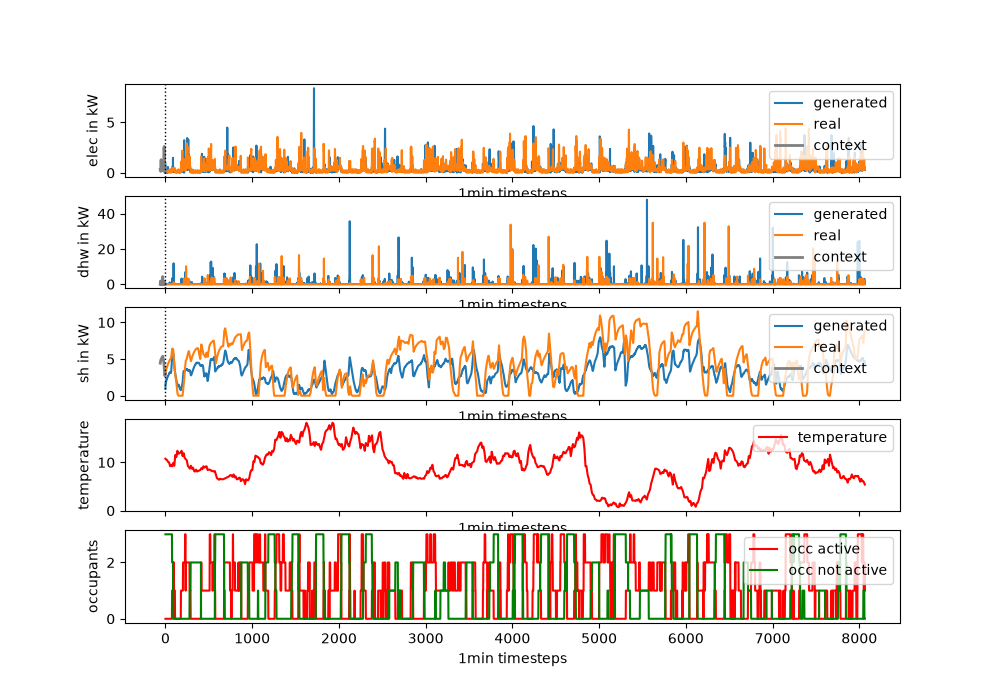

In [28]:
i =8

occ = condition[i]
load = x[i]
load_real = real[i]

occ_activ, occ_not_active, temp = occ[0],occ[1], occ[2]
elec_gen, dhw_gen, sh_gen = load[0], load[1], load[2]
elec_real, dhw_real, sh_real = load_real [0], load_real [1], load_real [2]


fig, ax = plt.subplots(5,1, figsize=(10,7), sharex=True)

ax[0].plot(elec_gen, label="generated")
ax[0].plot(elec_real, label="real")
ax[0].set_ylabel("elec in kW")
ax[0].set_xlabel("1min timesteps")


ax[1].plot(dhw_gen, label="generated")
ax[1].plot(dhw_real, label="real")
ax[1].set_ylabel("dhw in kW")
ax[1].set_xlabel("1min timesteps")


ax[2].plot(sh_gen, label="generated")
ax[2].plot(sh_real, label="real")
ax[2].set_ylabel("sh in kW")
ax[2].set_xlabel("1min timesteps")


ax[3].plot(temp, label="temperature", color="r")
ax[3].set_ylabel("temperature")
ax[3].set_xlabel("1min timesteps")
ax[3].legend(loc="upper right")

ax[4].plot(occ_activ, label="occ active", color="r")
ax[4].plot(occ_not_active, label="occ not active", color="g")
ax[4].set_ylabel("occupants")
ax[4].set_xlabel("1min timesteps")
ax[4].legend(loc="upper right")

for k in range(3):
    if has_ctx[i]:
        ax[k].plot(t_ctx, ctx[i, k], color="gray", lw=2, label="context")
    ax[k].axvline(0, color="k", ls=":", lw=1)
    ax[k].legend(loc="upper right")


In [25]:
from src.trainloop import validate

val_idx = pipe.Window_drawer("val", 1, 1, seed=0)          # the same draw as val_dataset_eval in training
val_dl = pipe.dataloader(pipe.windowdataset("val", val_idx), batchsize=32, num_workers=0)
val_loss, val_per_t = validate(net, schedule, val_dl, device, loss_type=c["loss_type"], n_batches=None)
print(val_loss, "| step:", ckpt["global_step"])

RuntimeError: Given groups=1, weight of size [64, 19, 3, 3], expected input[32, 15, 28, 288] to have 19 channels, but got 15 channels instead

In [34]:
import numpy as np
res = []
for b_i, batch in zip(range(16), dl):
    dyn = batch["condition"].to(device)
    x_gen = sample1d(net, cfg.window_length, dyn.shape[0], n_tgt, schedule,
                     batch["static_cat"].to(device), batch["static_cont"].to(device), batch["static_bool"].to(device),
                     dyn=dyn, clip_range=(x0_min, x0_max), sampler="dpm", cond=cond)
    cond1 = batch["condition"]
    has = cond1[:, s0 + n_tgt, 0] > 0
    last = cond1[:, s0:s0 + n_tgt, 0 if cfg.context_reverse else K - 1]     # last context step, scaled
    res.append(dict(
        bias=(x_gen.mean(2) - batch["target"].mean(2)),                      # (B, n_tgt)
        gap_gen=(x_gen[:, :, 0] - last).abs()[has],
        gap_real=(batch["target"][:, :, 0] - last).abs()[has]))
print("mean bias per channel:", torch.cat([r["bias"] for r in res]).mean(0))
print("boundary gap gen :", torch.cat([r["gap_gen"] for r in res]).mean(0))
print("boundary gap real:", torch.cat([r["gap_real"] for r in res]).mean(0))

mean bias per channel: tensor([-0.0246, -0.0014,  0.0047])
boundary gap gen : tensor([0.1582, 0.0690, 0.0060])
boundary gap real: tensor([0.1031, 0.0440, 0.0027])


In [17]:
cfg.window_length

1440

In [59]:
def year_conditions(ds, run_id, path, window_length):
    _, cond, season = ds._read_series(path)
    cond = apply_scaler(cond / ds.condition_norm[run_id], ds.condition_scaler)
    if season is not None:                       # appended after scaling, like in h5Dataset
        cond = np.concatenate([cond, season], axis=0)
    n_steps = cond.shape[1]
    n_win = math.ceil(n_steps / window_length)
    cond = np.pad(cond, ((0, 0), (0, n_win * window_length - n_steps)), mode="edge")
    windows = [torch.from_numpy(np.ascontiguousarray(cond[:, w * window_length:(w + 1) * window_length]))[None].float() for w in range(n_win)]
    return windows, n_steps

file_nr = -4
days, n_steps = year_conditions(ds, val_run_ids[file_nr], val_files[file_nr], cfg.window_length)

In [60]:
B = 8
dyn_days = [d.repeat(B, 1, 1).to(device) for d in days]
static = val_static[val_run_ids[file_nr]]                                         # same dict h5Dataset uses
static_cat  = static["categorical"][None].repeat(B, 1).to(device)
static_cont = static["continuous"][None].repeat(B, 1).to(device)
static_bool = static["boolean"][None].repeat(B, 1).to(device)

In [61]:
static

{'categorical': tensor([ 4, 12,  3,  7]),
 'continuous': tensor([-0.7517, -0.8500, -0.8329,  0.4573,  0.4537,  3.2634,  0.4621, -0.9218,
          2.7742,  1.5905, -1.8016,  0.4435, -1.2649,  0.4369,  0.2242,  0.5517,
          1.0481, -2.1467,  0.4535, -1.9020, -4.6398, -1.1104,  0.2031,  1.1364,
          2.9207, -0.8404,  0.3620,  0.4646, -0.5622,  0.7329]),
 'boolean': tensor([])}

In [62]:
static_cat

tensor([[ 4, 12,  3,  7],
        [ 4, 12,  3,  7],
        [ 4, 12,  3,  7],
        [ 4, 12,  3,  7],
        [ 4, 12,  3,  7],
        [ 4, 12,  3,  7],
        [ 4, 12,  3,  7],
        [ 4, 12,  3,  7]], device='cuda:0')

In [63]:


y, c = sample_year(net, schedule, dyn_days, static_cat, static_cont, static_bool , cfg.context_steps, len(cfg.target_cols), cfg.window_length,
                   reverse=cfg.context_reverse, clip_range=pipe.x0_minmax(),
                   cond=cond, sampler="dpm", num_steps=100)

days:   0%|          | 0/14 [00:00<?, ?it/s]

In [64]:
raw = invert_scaler(y.cpu(), pipe.target_scaler) * ds.target_norm[val_run_ids[file_nr]]
n_dyn = len(cfg.dynamic_cond_cols)
c = c.cpu()
raw_cond = invert_scaler(c[:, :n_dyn].clone(), pipe.condition_scaler) * ds.condition_norm[val_run_ids[file_nr]]
season = c[:, n_dyn:]

C:\Users\Samuel\AppData\Local\Temp\ipykernel_14536\2071632234.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  raw = invert_scaler(y.cpu(), pipe.target_scaler) * ds.target_norm[val_run_ids[file_nr]]
C:\Users\Samuel\AppData\Local\Temp\ipykernel_14536\2071632234.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  raw_cond = invert_scaler(c[:, :n_dyn].clone(), pipe.condition_scaler) * ds.condition_norm[val_run_ids[file_nr]]


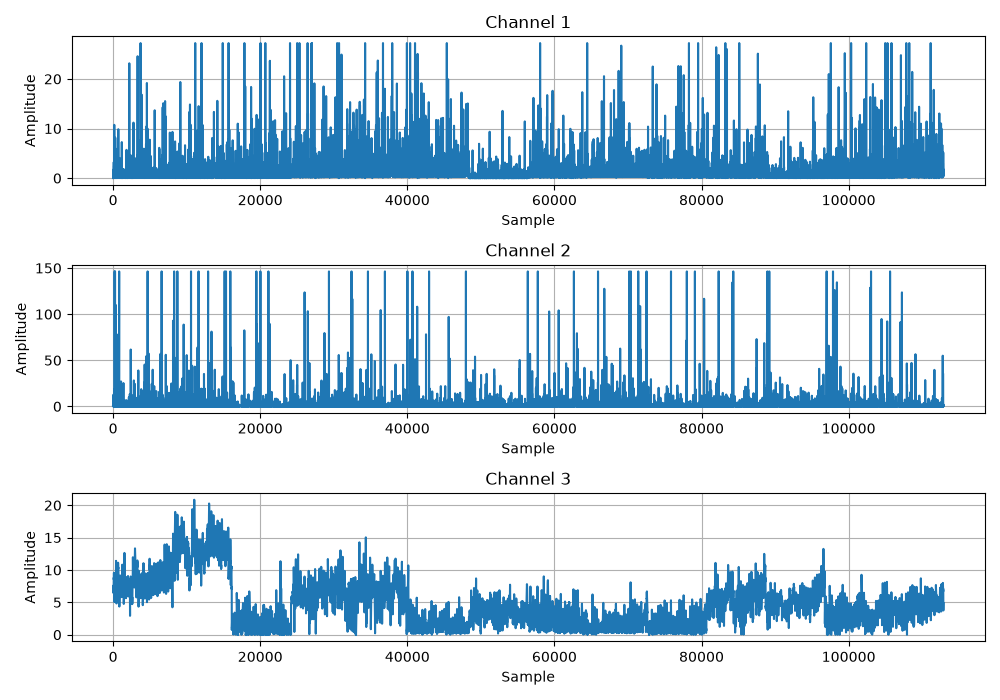

In [65]:
import matplotlib.pyplot as plt

# Tensor shape: [4, 3, 525600]
batch = raw[5]  # Shape: [3, 525600]

fig, axes = plt.subplots(3, 1, figsize=(10, 7))

for i in range(3):
    axes[i].plot(batch[i].detach().cpu().numpy())
    axes[i].set_title(f"Channel {i + 1}")
    axes[i].set_xlabel("Sample")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [66]:
real_year_data = pd.read_hdf(val_files[file_nr], key="timeseries").resample("5min").agg(cfg.ts_agg)
real_year_data

,T,Occupancy Home Active,Occupancy Home Not Active,Electricity Load,Hot Water Load,Heating Load,Off Day
2018-01-01 00:00:00+01:00,8.0,0.0,3.0,0.042248,0.0,8.748550e-12,1
2018-01-01 00:05:00+01:00,8.0,0.0,3.0,0.042248,0.0,8.748550e-12,1
2018-01-01 00:10:00+01:00,8.0,0.0,3.0,0.042248,0.0,8.748550e-12,1
2018-01-01 00:15:00+01:00,8.0,0.0,3.0,0.042248,0.0,8.748550e-12,1
2018-01-01 00:20:00+01:00,8.0,0.0,3.0,0.042248,0.0,8.748550e-12,1
...,...,...,...,...,...,...,...
2018-12-31 23:35:00+01:00,8.5,1.0,1.0,0.495024,0.0,5.466830e-01,0
2018-12-31 23:40:00+01:00,8.5,1.0,1.0,0.446805,0.0,5.466830e-01,0
2018-12-31 23:45:00+01:00,8.5,1.0,1.0,0.304771,0.0,5.466830e-01,0
2018-12-31 23:50:00+01:00,8.5,1.0,1.0,0.352087,0.0,5.466830e-01,0


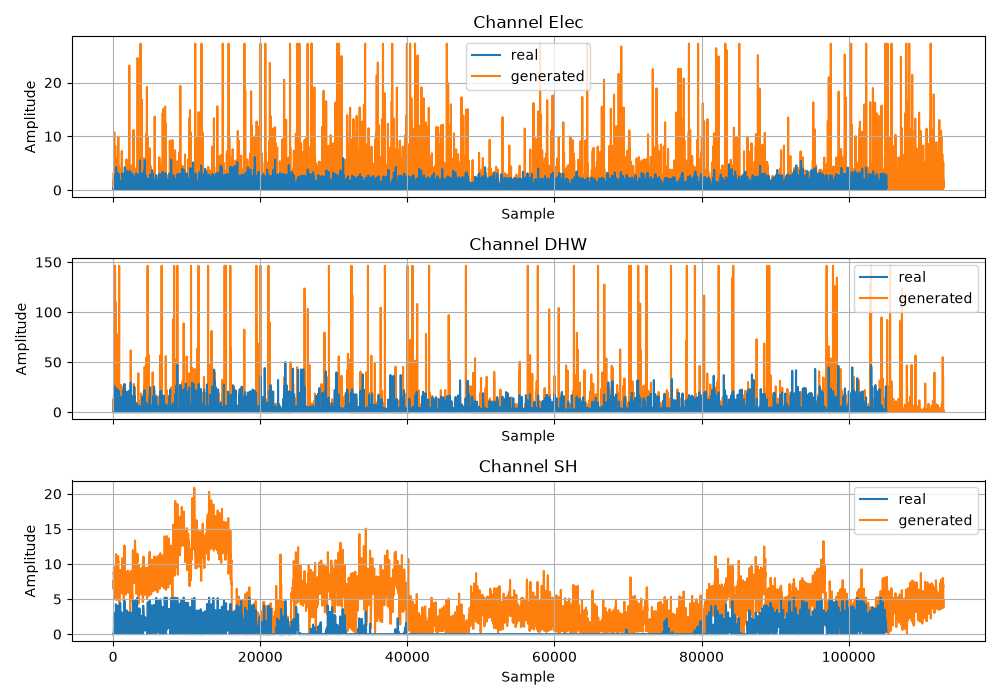

In [67]:
import matplotlib.pyplot as plt
batch = raw[5]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

axes[0].plot(real_year_data["Electricity Load"].reset_index(drop=True), zorder=1, label="real")
axes[0].plot(batch[0].detach().cpu().numpy(), zorder=0, label="generated")
axes[0].set_title(f"Channel Elec")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)
axes[0].legend()
axes[1].plot(real_year_data["Hot Water Load"].reset_index(drop=True), label="real",zorder=1)
axes[1].plot(batch[1].detach().cpu().numpy(), label="generated", zorder=0)
axes[1].set_title(f"Channel DHW")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)
axes[1].legend()
axes[2].plot(real_year_data["Heating Load"].reset_index(drop=True), label="real",zorder=1)
axes[2].plot(batch[2].detach().cpu().numpy(), label="generated", zorder=0)
axes[2].set_title(f"Channel SH")
axes[2].set_xlabel("Sample")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True)
axes[2].legend()
plt.tight_layout()
plt.show()

In [72]:
w, nw = 8064, 13
m = y[..., :nw*w].reshape(y.shape[0], y.shape[1], nw, w).mean(-1)      # (B, C, windows)
real_m = real[:, :nw*w].reshape(real.shape[0], nw, w).mean(-1)          # (C, windows)
print("spread between samples:", m.std(0).mean(-1))
print("abs error vs real:     ", (m - real_m).abs().mean((0, 2)))
print("real window mean size: ", real_m.abs().mean(-1))

RuntimeError: shape '[32, 13, 8064]' is invalid for input of size 774144

In [45]:
lo, hi = pipe.x0_minmax()
print(y.min(), y.max(), (y >= 0.999*hi.cpu()).float().mean())

tensor(-0.9994) tensor(15.1593) tensor(0.0003)


In [46]:
import numpy as np
lo, hi = pipe.x0_minmax()
sat = (y[0] >= 0.999 * hi.cpu()).any(0).numpy()      # (L,) saturated at any channel; y: (B, C, L)
idx = np.nonzero(sat)[0]
print("fraction saturated:", sat.mean(), "| y range:", y.min().item(), y.max().item())
print("by position in window:", np.bincount(idx % 8064, minlength=8064).reshape(-1, 288).sum(0).argmax())
print("share in first/last 288 steps of a window:",
      np.mean((idx % 8064 < 288) | (idx % 8064 >= 8064 - 288)))
print("co-occurring across channels:", ((y[0] >= 0.999 * hi.cpu()).sum(0) > 1).float().mean().item())

fraction saturated: 0.0002982095616024187 | y range: -0.9993703961372375 15.159257888793945
by position in window: 1
share in first/last 288 steps of a window: 1.0
co-occurring across channels: 0.0
